# **1. Introduction**

**Insurance Premium Prediction Using Decision Tree**

This project aims to predict insurance expenses based on customer information using a Decision Tree Regression model. The dataset contains features such as age, sex, BMI, number of children, smoking status, and region.

The notebook covers the main stages of a machine learning workflow, including Exploratory Data Analysis (EDA), data preprocessing, model training, and model evaluation. The goal is to understand the factors affecting insurance charges and evaluate how accurately a Decision Tree model can predict insurance costs based on the available data.

## **2. Algorithm explanation**



Decision Tree Regression
1. What is the algorithm?
A machine learning algorithm that predicts continuous numerical values by splitting data into branches.

2. How does it work?
It repeatedly splits data based on feature values and predicts the average target value at each leaf node.

3. When should it be used?
When predicting numerical values, such as house prices, especially when relationships are nonlinear.

4. Advantages and limitations?
- Advantages: Easy to understand, visualize, and interpret.
- Limitations: Can overfit and perform poorly on unseen data if not properly controlled.

# **3. Dataset exploration (EDA)** - Raghad

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import kagglehub
import os

path = kagglehub.dataset_download("noordeen/insurance-premium-prediction")
print(os.listdir(path))

Using Colab cache for faster access to the 'insurance-premium-prediction' dataset.
['insurance.csv']


In [ ]:
df = pd.read_csv(os.path.join(path, "insurance.csv"))
df.head()

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [ ]:
# Check missing values
print(df.isnull().sum())

# Descriptive Statistics
print(df.describe())

# Categorical Feature Distribution
print(df['sex'].value_counts(),"\n")
print(df['smoker'].value_counts(),"\n")
print(df['region'].value_counts(),"\n")

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
expenses    0
dtype: int64
               age          bmi     children      expenses
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.665471     1.094918  13270.422414
std      14.049960     6.098382     1.205493  12110.011240
min      18.000000    16.000000     0.000000   1121.870000
25%      27.000000    26.300000     0.000000   4740.287500
50%      39.000000    30.400000     1.000000   9382.030000
75%      51.000000    34.700000     2.000000  16639.915000
max      64.000000    53.100000     5.000000  63770.430000
sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 



Key Observations:


*   expenses is highly right-skewed (mean = 13,270 vs. median = 9,382)
*   age ranges from 18 to 64 (working-age adults)
*   bmi ranges from 16 to 53 (includes underweight to obese)
*   children number ranges from 0 to 5
*   sex and region are balanced
*   smoker is imbalanced (~80% non-smokers, 20% smokers)

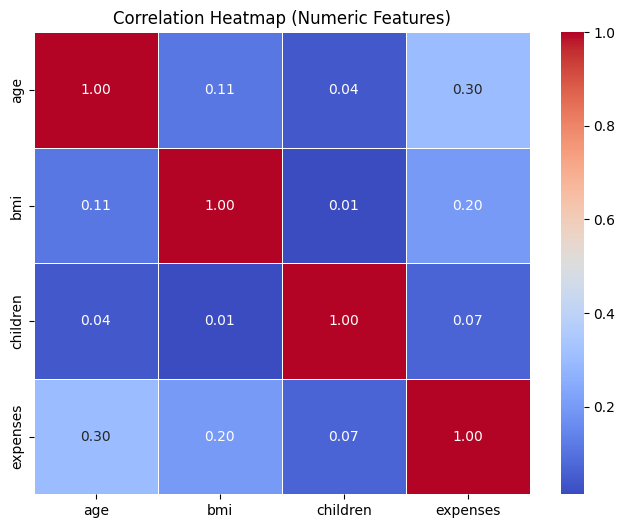

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(8, 6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap (Numeric Features)')
plt.show()

**Observations:**

- `age` has the strongest linear correlation with expenses (0.30).

- `bmi` shows a moderate positive correlation (0.20).

- `children` has very weak correlation (0.07).

- No multicollinearity among predictors (all pairwise correlations are low).

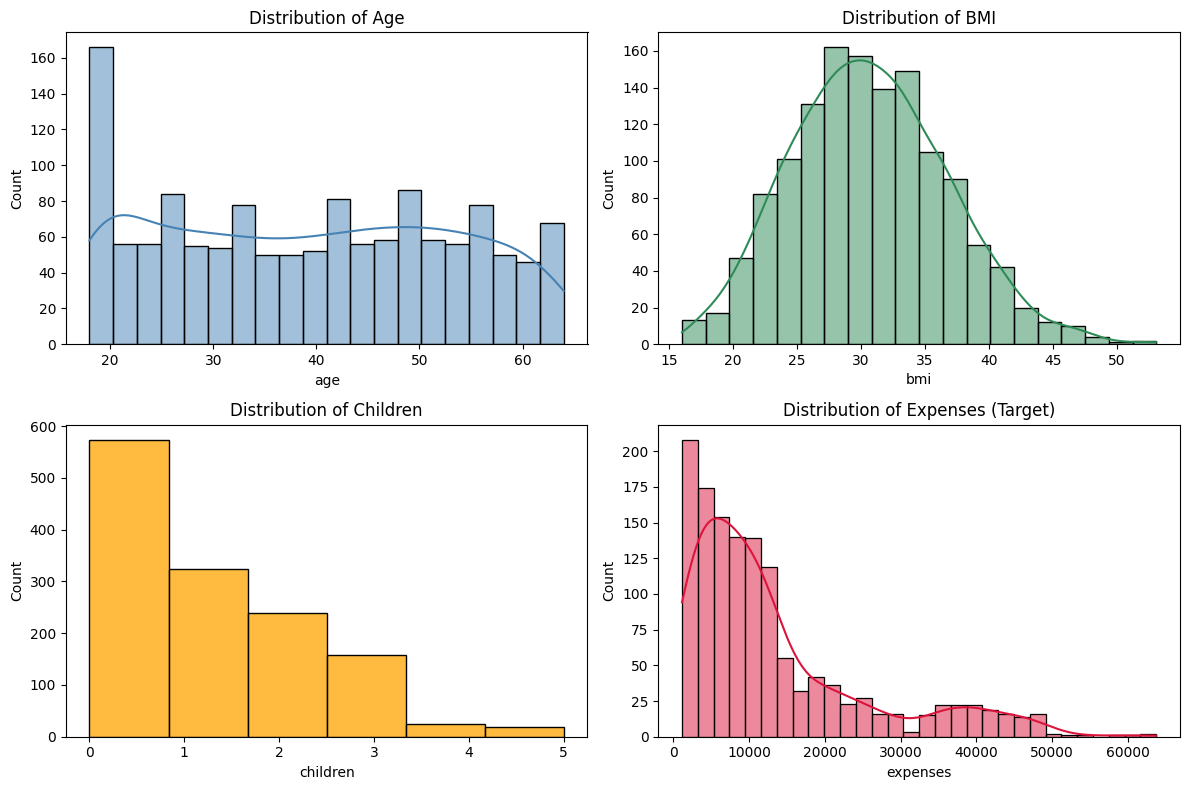

In [ ]:
# Histograms: Distribution of Numeric Features
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['age'], bins=20, kde=True, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Distribution of Age')

sns.histplot(df['bmi'], bins=20, kde=True, ax=axes[0,1], color='seagreen')
axes[0,1].set_title('Distribution of BMI')

sns.histplot(df['children'], bins=6, kde=False, ax=axes[1,0], color='orange')
axes[1,0].set_title('Distribution of Children')

sns.histplot(df['expenses'], bins=30, kde=True, ax=axes[1,1], color='crimson')
axes[1,1].set_title('Distribution of Expenses (Target)')

plt.tight_layout()
plt.show()

**Observations:**

- `age` is fairly uniform (no strong skew).

- `bmi` is roughly normal (slight right tail).

- `children` is right-skewed (most have 0–2 children).

- `expenses` is strongly right-skewed with most people have low costs, but a few have very high costs.

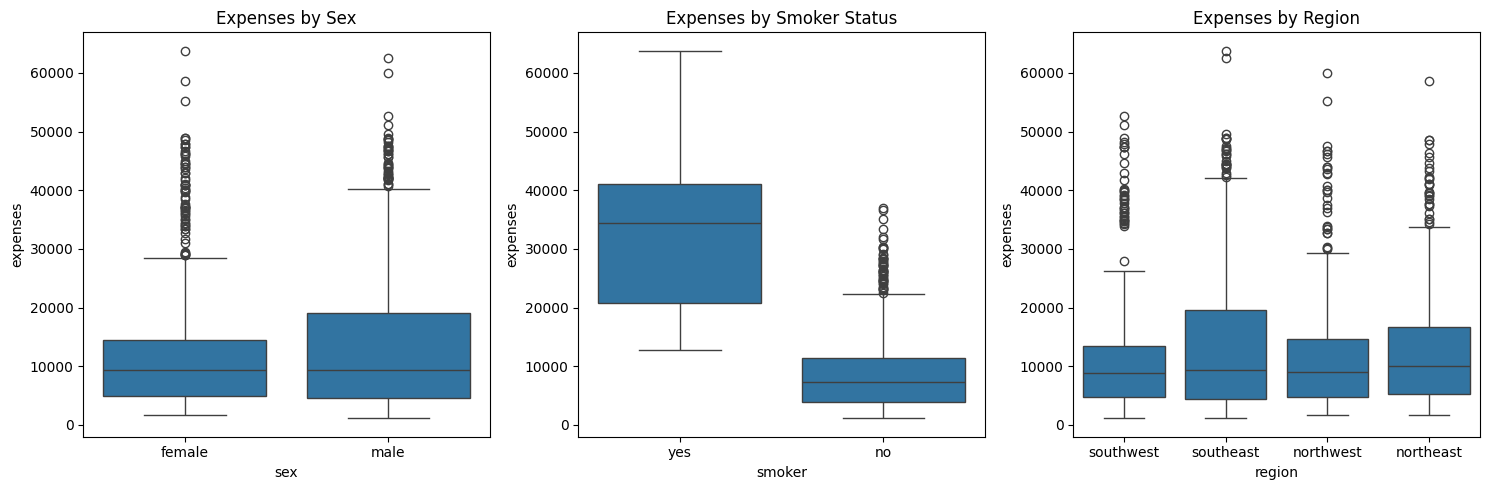

In [ ]:
# Boxplots: Expenses by Categorical Features
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(x='sex', y='expenses', data=df, ax=axes[0])
axes[0].set_title('Expenses by Sex')

sns.boxplot(x='smoker', y='expenses', data=df, ax=axes[1])
axes[1].set_title('Expenses by Smoker Status')

sns.boxplot(x='region', y='expenses', data=df, ax=axes[2])
axes[2].set_title('Expenses by Region')

plt.tight_layout()
plt.show()

**Observations:**

- `Smoker` status is the strongest categorical predictor, smokers have dramatically higher expenses.

- `sex` shows little difference.

- `region` shows minor differences (southeast slightly higher).

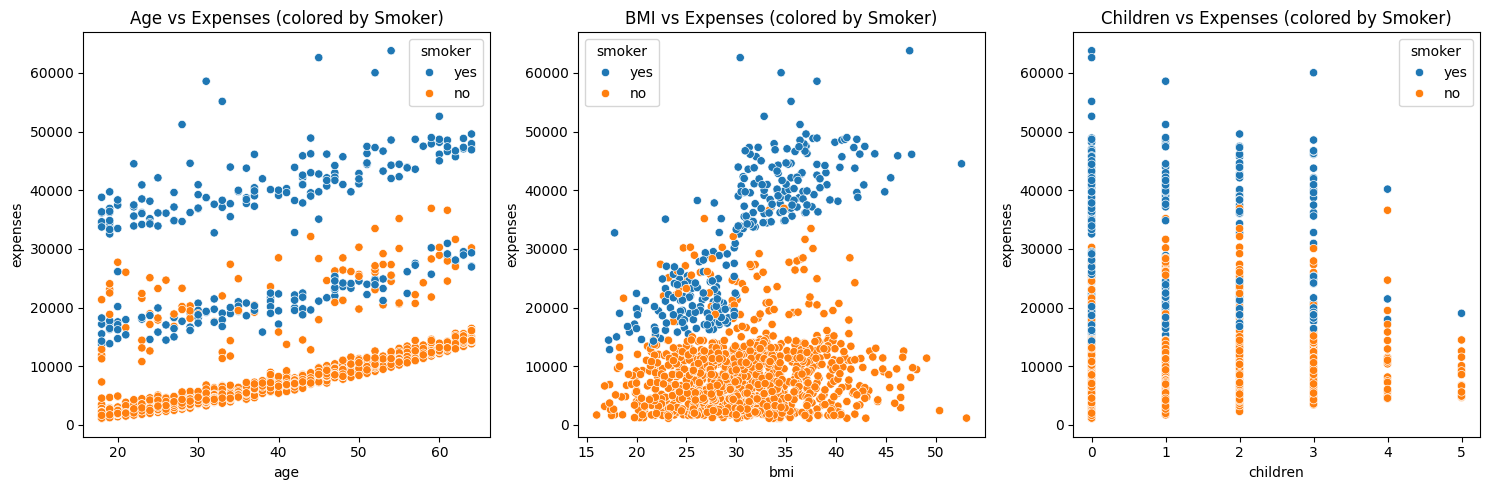

In [ ]:
# Scatter Plots: Numeric Features vs. Expenses
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.scatterplot(x='age', y='expenses', hue='smoker', data=df, ax=axes[0])
axes[0].set_title('Age vs Expenses (colored by Smoker)')

sns.scatterplot(x='bmi', y='expenses', hue='smoker', data=df, ax=axes[1])
axes[1].set_title('BMI vs Expenses (colored by Smoker)')

sns.scatterplot(x='children', y='expenses', hue='smoker', data=df, ax=axes[2])
axes[2].set_title('Children vs Expenses (colored by Smoker)')

plt.tight_layout()
plt.show()

**Observations:**

- **Age** vs **Expenses**: Positive trend, where older people tend to have higher costs. Smokers form a separate, higher band.

- **BMI** vs **Expenses**: For smokers, BMI strongly correlates with higher expenses (visible upward slope in the orange/red dots). For non-smokers, the relationship is weak.

- **Children** vs **Expenses**: No strong direct relationship.

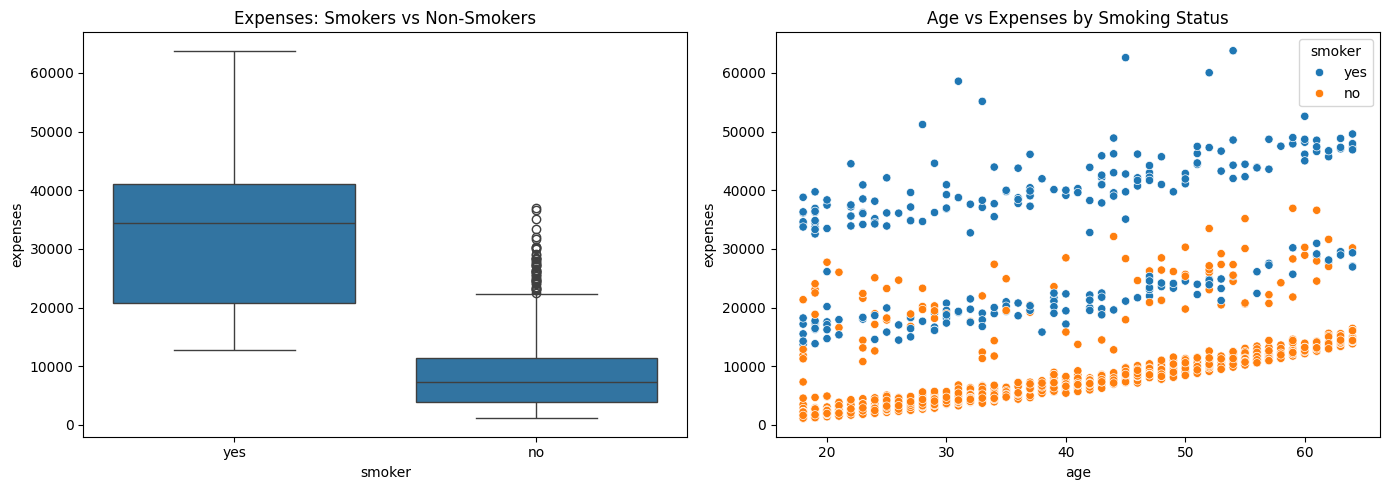

In [ ]:
# A better look into the top-2 features
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='smoker', y='expenses', data=df, ax=axes[0])
axes[0].set_title('Expenses: Smokers vs Non-Smokers')

sns.scatterplot(x='age', y='expenses', hue='smoker', data=df, ax=axes[1])
axes[1].set_title('Age vs Expenses by Smoking Status')

plt.tight_layout()
plt.show()

**Observations:**

*   **Smokers** pay much higher expenses than non-smokers.
*   **Expenses** increase with age for both groups.
*   **Smoker** does not appear in the correlation heatmap because it is a categorical col, which is why this plot is needed.

# **4. Data preprocessing** - Ruba

In [ ]:
from sklearn.model_selection import train_test_split

data = df.copy()

# check missing values
print("Missing values:")
print(data.isnull().sum())

# remove duplicates
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates()
print("Shape after removing duplicates:", data.shape)

# encode sex and smoker
data["sex"] = data["sex"].map({"female": 0, "male": 1})
data["smoker"] = data["smoker"].map({"no": 0, "yes": 1})
print(data[["sex", "smoker"]].head())
data = pd.get_dummies(data, columns=["region"])

# encode reigon
region_columns = ["region_northeast", "region_northwest", "region_southeast", "region_southwest"]
data[region_columns] = data[region_columns].astype(int)

print(data.columns.tolist())
data.head()

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
expenses    0
dtype: int64
Duplicate rows: 1
Shape after removing duplicates: (1337, 7)
   sex  smoker
0    0       1
1    1       0
2    1       0
3    1       0
4    1       0
['age', 'sex', 'bmi', 'children', 'smoker', 'expenses', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest']


,age,sex,bmi,children,smoker,expenses,region_northeast,region_northwest,region_southeast,region_southwest
0,19,0,27.9,0,1,16884.92,0,0,0,1
1,18,1,33.8,1,0,1725.55,0,0,1,0
2,28,1,33.0,3,0,4449.46,0,0,1,0
3,33,1,22.7,0,0,21984.47,0,1,0,0
4,32,1,28.9,0,0,3866.86,0,1,0,0


# **5. Model training** - Daniyah

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# 1. Separate features and target
X = data.drop("expenses", axis=1)
y = data["expenses"]

# 2. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Create the Decision Tree model
model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# 4. Train the model
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# **6. Model evaluation** - Omar

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import plot_tree
# 1. Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test, y_pred)

# 2. Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)

# 3. Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

# 4. R² Score (Coefficient of Determination)
r2 = r2_score(y_test, y_pred)

# Show the results
print(f"MAE: {mae:,.2f}")
print(f"MSE:  {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.3f}")

MAE: 2,609.32
MSE:  19,268,544.69
RMSE: 4,389.60
R²:   0.895


**Interpreting the results:**

*   R² = 0.895: The model explains about 89.5% of the variation in insurance expenses, which is a strong result.
*   MAE = \$2,609: On average, the model's predictions are off by about \$2,609.
*   RMSE = \$4,390: RMSE is much higher than MAE, which means a few predictions have large errors. These are likely the high-cost customers, whose expenses are harder to predict.
*   MSE: It is in squared dollars, so it is hard to explain on its own. It is mainly useful for comparing models.

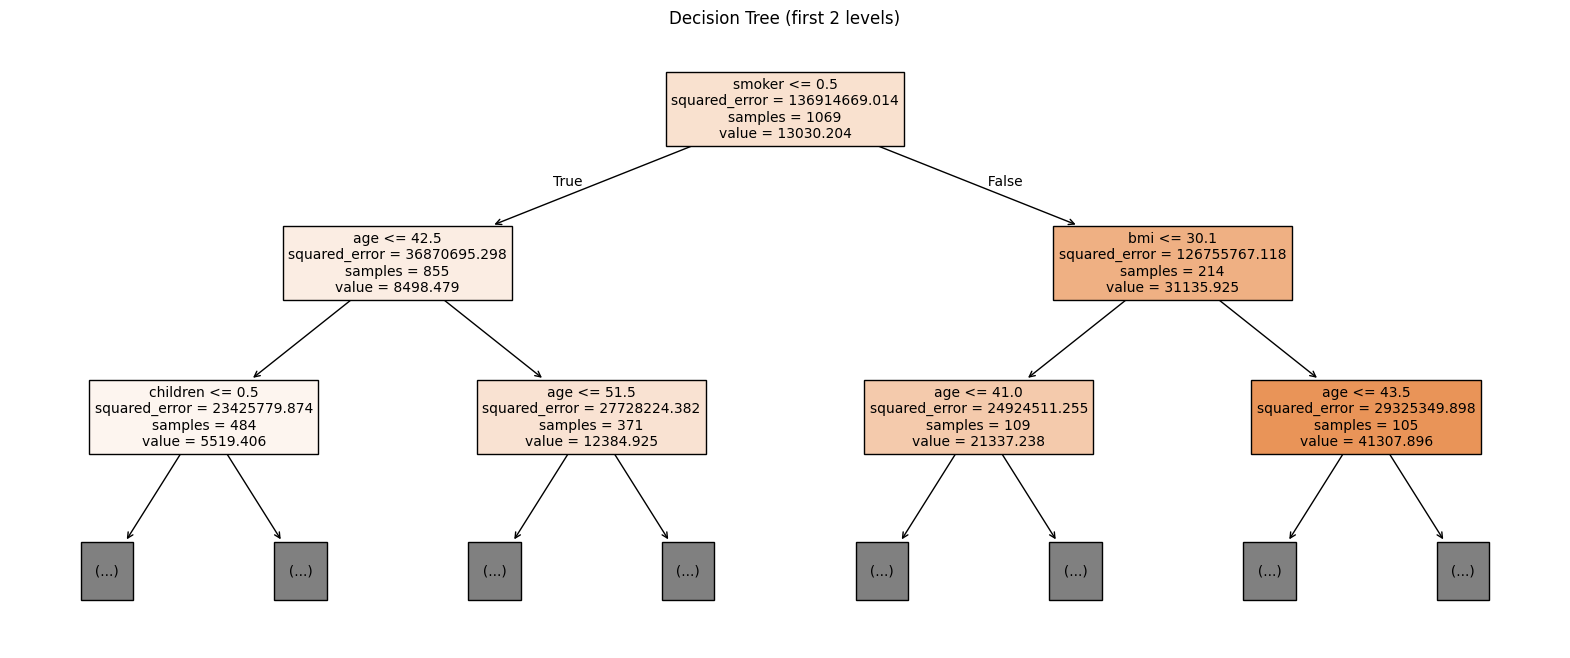

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(model, feature_names=X.columns, filled=True, max_depth=2, fontsize=10)
plt.title('Decision Tree (first 2 levels)')
plt.show()

# **7. Conclusion**

In this project, we used a Decision Tree Regression model to predict insurance expenses from customer information.

**Key findings:**

*   The model performed well, with an R² of 0.895, meaning it explains about 89.5% of the variation in insurance expenses.
*   Predictions are off by about \$2,609 on average (MAE).
*   Smoking status is the strongest factor affecting expenses, followed by BMI and age. This was clear in both the EDA and the model's feature importance.
*   Limiting the tree (max_depth=5, min_samples_leaf=5) kept the model simple and reduced the risk of overfitting.

**Limitations:**

*   RMSE (\$4,390) is much higher than MAE, so the model still makes some large errors, mostly on high-cost customers.
*   A single decision tree gives step-like predictions, since everyone in the same leaf gets the same value.

**Possible improvements:**

*   Tuning the hyperparameters using GridSearchCV.
*   Trying a Random Forest, which combines many trees and usually gives more accurate and stable predictions.